<img src="https://full-stack-assets.s3.eu-west-3.amazonaws.com/M08-deep-learning/AT%26T_logo_2016.svg" alt="AT&T LOGO" width="50%" />

# Orange SPAM detector

## Company's Description 📇

AT&T Inc. is an American multinational telecommunications holding company headquartered at Whitacre Tower in Downtown Dallas, Texas. It is the world's largest telecommunications company by revenue and the third largest provider of mobile telephone services in the U.S. As of 2022, AT&T was ranked 13th on the Fortune 500 rankings of the largest United States corporations, with revenues of $168.8 billion! 😮

## Project 🚧

One of the main pain point that AT&T users are facing is constant exposure to SPAM messages.

AT&T has been able to manually flag spam messages for a time, but they are looking for an automated way of detecting spams to protect their users.

## Goals 🎯

Your goal is to build a spam detector, that can automatically flag spams as they come based solely on the sms' content.

## Scope of this project 🖼️

To start off, AT&T would like you to use the folowing dataset:

[Dowload the Dataset](https://full-stack-bigdata-datasets.s3.eu-west-3.amazonaws.com/Deep+Learning/project/spam.csv)

## Helpers 🦮

To help you achieve this project, here are a few tips that should help you: 

### Start simple
A good deep learing model does not necessarily have to be super complicated!

### Transfer learning
You do not have access to a whole lot of data, perhaps channeling the power of a more sophisticated model trained on billions of observations might help!

## Deliverable 📬

To complete this project, your team should: 

* Write a notebook that runs preprocessing and trains one or more deep learning models in order to predict the spam or ham nature of the sms
* State the achieved performance clearly

## 1. Exploration des données

### Chargement et premier aperçu

In [1]:
import pandas as pd

df = pd.read_csv("data/raw/spam.csv", encoding="latin-1")
print(df.shape)


(5572, 5)


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   v1          5572 non-null   object
 1   v2          5572 non-null   object
 2   Unnamed: 2  50 non-null     object
 3   Unnamed: 3  12 non-null     object
 4   Unnamed: 4  6 non-null      object
dtypes: object(5)
memory usage: 217.8+ KB


In [3]:
df.head(10)

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN
5,spam,FreeMsg Hey there darling it's been 3 week's n...,NaN,NaN,NaN
6,ham,Even my brother is not like to speak with me. ...,NaN,NaN,NaN
7,ham,As per your request 'Melle Melle (Oru Minnamin...,NaN,NaN,NaN
8,spam,WINNER!! As a valued network customer you have...,NaN,NaN,NaN
9,spam,Had your mobile 11 months or more? U R entitle...,NaN,NaN,NaN


Nous notons que les colonnes 1 et 2 sont entièrement remplies, mais il y a présence de trois autres colonnes sans nom et très faiblement remplies : seulement 50 valeurs sur la première des trois colonnes, 12 pour la deuxième et 6 pour la troisième. 
Nous allons examiner de plus près ces messages et déterminer si ces colonnes peuvent être supprimées ou non. 

In [4]:
pd.set_option("display.max_colwidth", None)
df[df["Unnamed: 2"].notna()].head(8)

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
95,spam,"Your free ringtone is waiting to be collected. Simply text the password \MIX\"" to 85069 to verify. Get Usher and Britney. FML",PO Box 5249,"MK17 92H. 450Ppw 16""",NaN
281,ham,\Wen u miss someone,the person is definitely special for u..... But if the person is so special,why to miss them,"just Keep-in-touch\"" gdeve.."""
444,ham,\HEY HEY WERETHE MONKEESPEOPLE SAY WE MONKEYAROUND! HOWDY GORGEOUS,"HOWU DOIN? FOUNDURSELF A JOBYET SAUSAGE?LOVE JEN XXX\""""",NaN,NaN
671,spam,SMS. ac sun0819 posts HELLO:\You seem cool,"wanted to say hi. HI!!!\"" Stop? Send STOP to 62468""",NaN,NaN
710,ham,Height of Confidence: All the Aeronautics professors wer calld &amp; they wer askd 2 sit in an aeroplane. Aftr they sat they wer told dat the plane ws made by their students. Dey all hurried out of d plane.. Bt only 1 didnt move... He said:\if it is made by my students,"this wont even start........ Datz confidence..""",NaN,NaN
899,spam,"Your free ringtone is waiting to be collected. Simply text the password \MIX\"" to 85069 to verify. Get Usher and Britney. FML",PO Box 5249,"MK17 92H. 450Ppw 16""",NaN
1038,ham,"Edison has rightly said, \A fool can ask more questions than a wise man can answer\"" Now you know why all of us are speechless during ViVa.. GM",GN,GE,"GNT:-)"""
1127,ham,"Height of \Oh shit....!!\"" situation: A guy throws a luv letter on a gal but falls on her brothers head whos a gay",".;-):-D""",NaN,NaN


Les fragments de messages présents dans les trois dernières colonnes semblent être dans la continuité du message principal qui est dans la deuxieme colonne. Nous en déduisons qu'il s'agit probablement d'une erreur de mise en forme liée au CSV qui se repère par rapport à des virgules pour pouvoir déterminer le changement de colonne. Au lieu de supprimer ces colonnes qui constituent une part de l'information pertinente, il convient donc de les rattacher à la colonne principale. À l'issue du processus, le data frame ne contiendra que deux colonnes : la classification spam/ham ainsi que le texte, mais il aura conservé l'intégralité de l'information initialement disponible. 

### Reconstitution des messages coupés

In [5]:
text_columns = ["v2", "Unnamed: 2", "Unnamed: 3", "Unnamed: 4"]
df["text"] = df[text_columns].apply(lambda row: ",".join(row.dropna()), axis=1)
df["text"] = df["text"].str.replace("\\", "", regex=False).str.strip()
df = df.rename(columns={"v1": "label"})[["label", "text"]]
print(df.shape)

(5572, 2)


In [6]:
df.loc[[95, 281, 444]]

,label,text
95,spam,"Your free ringtone is waiting to be collected. Simply text the password MIX"" to 85069 to verify. Get Usher and Britney. FML, PO Box 5249, MK17 92H. 450Ppw 16"""
281,ham,"Wen u miss someone, the person is definitely special for u..... But if the person is so special, why to miss them, just Keep-in-touch"" gdeve.."""
444,ham,"HEY HEY WERETHE MONKEESPEOPLE SAY WE MONKEYAROUND! HOWDY GORGEOUS, HOWU DOIN? FOUNDURSELF A JOBYET SAUSAGE?LOVE JEN XXX"""""


### Suppression des doublons

En observant le corpus et en particulier les cellules qui avaient été découpées par le CSV, on observe des duplicats. Par exemple, la ligne 899 est exactement la même que la ligne 95. Nous allons donc chercher les doublons. 

In [7]:
print(df["text"].duplicated().sum(), "doublons")

414 doublons


Le corpus contient 414 doublons qu'il convient de supprimer. 

In [8]:
df = df.drop_duplicates(subset="text").reset_index(drop=True)
print(df.shape)
df["label"].value_counts()

(5158, 2)


label
ham     4516
spam     642
Name: count, dtype: int64

Le corpus a maintenant été nettoyé de ses doublons. Il est constitué de 5 158 SMS, dont 642 sont des spams (12,4%). 

### Longueur des messages
Nous nous intéressons maintenant à la longueur des messages, mesurée en nombre de mots par SMS

In [9]:
import plotly.express as px

df["n_words"] = df["text"].str.split().str.len()
print(df.groupby("label")["n_words"].describe())
fig = px.histogram(df, x="n_words", color="label", barmode="overlay", nbins=60,
                   title="Nombre de mots par SMS selon la classe")
fig.show()

        count       mean        std  min    25%   50%   75%    max
label                                                             
ham    4516.0  14.237378  11.166688  1.0   7.00  11.0  19.0  171.0
spam    642.0  23.699377   5.968584  2.0  21.25  25.0  28.0   35.0


Les deux catégories ham et spam ont des structures manifestement différentes, notamment en termes de longueur. Les spams ont une tendance à être plus longs que les hams (mediane: 22 contre 11) et présente un écart type relativement faible (5.7). Les hams, quant à eux, sont plus courst que les spams, avec un écart type plus important (11.5). 

## 2. Préparation des données

L'objectif est de prédire si un SMS est un spam ou non à partir de son contenu. Nous disposons pour cela d'un jeu de données que nous allons utiliser afin d'entraîner des réseaux de neurones tel que demandé. 

Nous allons d'abord construire un premier réseau sans pré entrainement préalable, c'est-à-dire que nous commençons à zéro. 
Dans une prochaine partie, nous utiliserons un modèle préentraîné sur un grand corpus de texte et nous l'adapterons. 

Dans les deux cas, nous allons avoir besoin de transformer les messages en matrices, ce sont les seules données qu'un réseau de neurones peut lire.

Le traitement des SMS ainsi que leur mise en forme matricielle se fera en trois étapes:
- Séparation des données en trois jeux
- Découpage des messages en tokens
- Ajustement de la longueur des SMS à une longueur commune 

### Séparation des données en trois jeux

Nous séparons les données en trois jeux. Le jeu d'entraînement (70 %) sert à apprendre. Les 30 % restants sont coupés en deux : un jeu de validation, sur lequel la performance est mesurée après chaque epoch pour surveiller l'apprentissage et repérer le surapprentissage, et un jeu de test, réservé à l'évaluation finale. Le découpage est stratifié afin de conserver la proportion de spams dans chaque jeu.

In [10]:
from sklearn.model_selection import train_test_split

X = df["text"]
y = (df["label"] == "spam").astype(int)

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)

for name, labels in [("train", y_train), ("validation", y_val), ("test", y_test)]:
    print(name, len(labels), round(labels.mean(), 3))

train 3610 0.124
validation 774 0.125
test 774 0.124


### Découpage des messages en tokens

Chaque SMS est d'abord tokenisé. Nous allons, pour cela, utiliser le tokenizer tiktoken (de GPT 4) qui est fourni par OpenAI. Chaque token du dictionnaire de ce tokenizer est référencé par un numéro d'index que nous allons utiliser pour représenter chaque phrase du corpus par un vecteur d'entiers et l'ensemble des phrases du corpus par une matrice. Le tokenizer possede un dictionnaire de plus de 100 000 tokens.

In [11]:
import tiktoken
import numpy as np

tokenizer = tiktoken.get_encoding("cl100k_base")      #Tokenizer fourni par Open AI
train_tokens = [tokenizer.encode(text) for text in X_train]
val_tokens = [tokenizer.encode(text) for text in X_val]
test_tokens = [tokenizer.encode(text) for text in X_test]

print(X_train.iloc[0])
print(train_tokens[0])

I also thk too fast... Xy suggest one not me. U dun wan it's ok. Going 2 rain leh where got gd.
[40, 1101, 270, 74, 2288, 5043, 1131, 1630, 88, 4284, 832, 539, 757, 13, 549, 50116, 78853, 433, 596, 5509, 13, 35971, 220, 17, 11422, 514, 71, 1405, 2751, 33730, 13]


In [12]:
print(tokenizer.n_vocab)    # nombre de token dans le dictionnaire du tokenizer

100277


Comme nous l'avons vu precedement, les SMS sont de tailles variées. Afin d'etablir la matrice nous avons besoin de vecteur de taille identique. Nous allons donc completer chaque vecteur avec autant de 0 que necessaire pour atteindre une longueur definie. Quelle longueur?
Pour ne perdre aucune information il faudrait considerer autant de dimensions pour chaque vecteur qu'il y a de token dans le SMS le plus long. Toutefois cela conduirait a une matrice de taille importante donc une grande partie serait constituee de 0. Afin d'optimiser le calcul il convient d'identifier une longueur ideale de message permettant de conserver une part importante de l'information, tout en reduisant la taille de la matrice.
Afin de déterminer cette longueur idéale, nous allons étudier la répartition de la longueur des SMS en tokens pour differents percentiles.   
Les SMS de longueur superieure a une longueur definie seront alors tronqués.   

La longueur des SMS doit être étudiée par classe. En effet, il convient de ne pas tronquer les SMS de type spam, car leur longueur est une caractéristique essentielle permettant de les distinguer. Nous savons, d'après l'histogramme établi précédemment, que L'essentiel des SMS longs qui seront tronqués seront des hams.

#### Longueur des messages en tokens

In [13]:
seq_lens = pd.Series([len(seq) for seq in train_tokens], index=X_train.index)
seq_lens.groupby(y_train).describe(percentiles=[0.5, 0.9, 0.95, 0.99])

,count,mean,std,min,50%,90%,95%,99%,max
label,,,,,,,,,
0,3161.0,19.207213,14.767408,1.0,14.0,38.0,46.0,73.40,185.0
1,449.0,41.244989,11.483009,6.0,43.0,55.0,58.0,62.04,67.0


Le spam le plus long du jeu d'entraînement compte 67 tokens : en coupant autour de 70, aucun spam n'est tronqué, chacun d'eux est conservé en entier. Nous allons affiner cette valeur en la calant sur le 99e percentile de l'ensemble des SMS, qui garantit en plus de conserver 99 % de tous les messages en entier.

#### Longueur commune

In [14]:
max_length = int(np.percentile(seq_lens, 99)) + 1
print(max_length)

72


La valeur entière juste au-dessus du 99e percentile est de 72 tokens : c'est la longueur que nous allons retenir pour couper les SMS. Elle est superieure à 67 tokens, longueur du spam le plus long, chaque spam est donc conservé en entier. Sans cette coupe, il aurait fallu considerer une matrice de 185 colonnes, rien que pour le jeu d'entraînement, et sans doute davantage afin de garder de la marge pour la production. En coupant à 72 tokens, nous reduisons la taille de la matrice d'un facteur supérieur à 2,5.

#### Mise à longueur commune des messages

In [15]:
def pad_sequences(sequences, max_length):           # sequences correspnd au corpus tokenisé (sous forme de liste de liste), len(sequences) correspond donc au nombre de SMS dans le corpus. max_length correspond au nombre maximal de token, precedement fixé à 72
    padded = np.zeros((len(sequences), max_length), dtype=np.int64)     #Creation d'une matrice remplie de 0.
    for i, seq in enumerate(sequences):
        seq = seq[:max_length]      #tronque les elements plus long que max_length, en laissant inchanger les elements plus courts
        padded[i, :len(seq)] = seq        #place chaque vecteur dans la matrice de 0
    return padded



On peut appliquer la fonction aux trois jeux de données

In [16]:
X_train_padded = pad_sequences(train_tokens, max_length)
X_val_padded = pad_sequences(val_tokens, max_length)
X_test_padded = pad_sequences(test_tokens, max_length)

print(X_train_padded.shape)
print(X_val_padded.shape)
print(X_test_padded.shape)

(3610, 72)
(774, 72)
(774, 72)


Les 3 matrices obtenue correspondent bien à l'ensemble total du jeu de données: 72 colonnes et 3610 + 774x2 = 5158 lignes.

Nous allons verifier combien de SMS ont été tronqués par classe:

In [17]:
print((seq_lens > max_length).groupby(y_train).sum())


label
0    34
1     0
dtype: int64


34 SMS ont été tronqués dans la classe ham et aucun dans la classe spam. 

In [18]:
X_train_padded[0]

array([   40,  1101,   270,    74,  2288,  5043,  1131,  1630,    88,
        4284,   832,   539,   757,    13,   549, 50116, 78853,   433,
         596,  5509,    13, 35971,   220,    17, 11422,   514,    71,
        1405,  2751, 33730,    13,     0,     0,     0,     0,     0,
           0,     0,     0,     0,     0,     0,     0,     0,     0,
           0,     0,     0,     0,     0,     0,     0,     0,     0,
           0,     0,     0,     0,     0,     0,     0,     0,     0,
           0,     0,     0,     0,     0,     0,     0,     0,     0])

Comme attendu, la matrice train est constituée d'un certain nombre d'index de tokens et est complétée par des zéros. 

## 3. Premier modèle : réseau construit de zéro

Nous allons ici construire et entraîner un premier réseau de neurones en utilisant la bibliothèque PyTorch. Il n'y a pas de pré-entraînement. Le modèle est construit de zéro. 
Pytorch necessite l'usage de tenseurs et une etape de conversion prealable des matrices est donc necessaire. Les SMS doivent etre converti en entiers car leurs vecteurs sont composés d'indices de token, nous utilierons donc un type long. 

Les jeux sont ensuite placés dans un dataoader qui vont s'occuper de gérer l'afflux de vecteurs à l'entrée du réseau. Le dataloader decoupe les données en paquets et les melanges entre chaque epoch lors de l'entrainement. Chaque epoch sera composée de batch de taille 32, c'est-à-dire que 32 SMS seront traités simultanément, en parallèle, dans les réseaux de neurones. Le nombre 32 est un choix arbitraire mais raisonnable, ayant pour objectif d'optimiser le calcul ( ne prenant qu'une partie des données) tout en stabilisant la descente de gradiant (en prenant plusieurs valeur simultanement). 


### Mise en forme des données pour PyTorch

In [19]:
import torch
from torch.utils.data import TensorDataset, DataLoader

X_train_tensor = torch.tensor(X_train_padded, dtype=torch.long)
X_val_tensor = torch.tensor(X_val_padded, dtype=torch.long)
X_test_tensor = torch.tensor(X_test_padded, dtype=torch.long)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val.values, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32)

batch_size = 32
train_loader = DataLoader(TensorDataset(X_train_tensor, y_train_tensor), batch_size=batch_size, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val_tensor, y_val_tensor), batch_size=batch_size, shuffle=False)
test_loader = DataLoader(TensorDataset(X_test_tensor, y_test_tensor), batch_size=batch_size, shuffle=False)

inputs, labels = next(iter(train_loader))
print(inputs.shape, inputs.dtype)
print(labels.shape, labels.dtype)
print(len(train_loader), len(val_loader), len(test_loader))

torch.Size([32, 72]) torch.int64
torch.Size([32]) torch.float32
113 25 25


Nous définissons maintenant le réseau de neurones comme une classe PyTorch. 
Chaque couche est déclarée dans init. L'enchaînement est ensuite décrit dans le forward. 

Pour la construction de ce modele nous nous baserons sur un modele vu lors de la formation: modele non sequentiel.
- couche d'embedding
- moyenne des vecteurs de tokens
- couche de sortie

### Architecture du réseau

#### Embedding

Jusque la les token ont ete utilises par leur indexe. Mais cet indexe n'est pas le porteur d'information, il constitu simplement un moyen d'identifier les tokens et d'assurer qu'un meme token soit traité de maniere identique partout dans le corpus. Pour que le réseau puisse travailler dessus, il faut associer à chaque index un vecteur de nombres. C'est le rôle de self.embedding.

self.embedding crée une table de 100 277 lignes, cela correspond au nombre de lignes presentes dans le dictionnaire de tiktoken. Chaque ligne est un vecteur de 32 nombres. Cette valeur de 32 est un choix arbitraire de conception. La dimension dépend de la quantité de données disponibles, de 8 pour un petit jeu de données, jusqu'à 1 024 pour de très gros corpus. La table est initialement remplie de valeurs aléatoires : les valeurs des vecteurs sont apprises pendant l'entraînement, comme les autres paramètres du réseau, de sorte que les tokens caractéristiques des spams et ceux des hams prennent des positions distinctes.

Il convient également de déclarer que la valeur 0 de la matrice ne correspond pas à un token mais à une absence de token. Avec padding_idx=0, la ligne 0 de la table est un vecteur nul, jamais mis à jour : elle n'apporte rien à la somme des vecteurs lors du moyennage. Elle reste toutefois comptée dans le dénominateur de la moyenne, qui divise toujours par 72.

Apres l'embedding on obtient un tenseur 3D (repere x, y, z)
Les axes correspondent initialement aux données suivantes:
- x liste les SMS (32 dans un mini-batch)
- y porte l'ensemble des token d'un SMS (72)
- z porte les coordonnées des vecteurs de token (nombre de dimension de l'espace d'embedding, fixée à 32)

Le teseur est donc initialement de forme (32, 72, 32).    



#### Pooling

Dans un modele avancé de deep learning, il sera possible d'utiliser des mecanismes de couches d'attention permmetant de ponderer les relations de chaque mot d'un SMS avec ses voisins. 
Le modele presenté ici est un modele elementaire, considerablement plus simple que les couches d'attention, et ne portant pas de notion semantique. Les relations entre les mots d'un SMS sont simplement etablis par un moyennage des valeurs des coordonnees de chaque token constituant le SMS.

C'est un modele qui presentes de nombreuses limites, notament l'ordre des mots n'est pas pris en compte. Le modele ne fait aucune distinction entre :
- "Le chat mange la souris"
- "La souris mange le chat"

Des couches d'attention auraient capturée la difference, mais ce n'est pas l'objectif ici, l'interpretation exacte du sens de la phrase n'est pas necessaire pour detecter un spam.

Le moyennage porte sur les 72 tokens d'un SMS : pour chacune des 32 coordonnées, on moyenne ses 72 valeurs. Ces tokens sont portés par l'axe y, or le pooling travaille sur le dernier axe, z. Il faut donc échanger y et z. c'est le role de la permutation (0, 2, 1).

apres permutation le tenseur prend donc la forme (32, 32, 72)

La moyenne est faite sur les 72 tokens, ce qui laisse un nombre unique par coordonnée et par SMS

A l'issue de ce moyennage le tenseur prend la forme (32, 32, 1)

Ce dernier axe n'est pas porteur d'information, le tenseur contient 32 × 32 = 1 024 éléments, autant qu'une matrice 32 × 32. On le retire avec squeeze(2), qui supprime l'axe d'index 2, donc le troisième : on obtient une matrice 32 x 32. Elle represente un vecteur de 32 coordonnées par SMS.      



#### Couche linéaire fc1

Apres le pooling, chaque SMS est un vecteur de 32 coordonnées. La couche linéaire self.fc1 contient 64 neurones et transforme donc un vecteur entrant de 32 valeurs en un vecteur de 64 valeurs : chaque sortie est une somme pondérée des 32 entrées, plus un biais. Les parametres de ponderations sont apris pendant l'entrainement.

C'est cette couche qui apprend à combiner les coordonnées des SMS pour en tirer des indices de spam ou de ham. Passer de 32 à 64 valeurs lui donne de la place pour construire plusieurs combinaisons différentes, dont la couche de sortie se servira ensuite.      



#### ReLU

self.relu est une fonction d'activation, appliquée à chacune des 64 sorties de la couche linéaire : elle met à zéro les valeurs négatives et laisse passer les valeurs positives telles quelles. 
Les fonctions d'activation sont necessaire pour assurer la non linearité du reseau.       



#### Dropout

Le dropout met à zero 30% des 64 valeurs issues de la ReLu, de maniere aleatoire. Il n'y a pas de parametre a apprendre lors de l'entrainement.
Il permet au reseau de ne pas toujours apprendre des memes neuronnes et limite l'overfitting.       



#### Couche de sortie fc2

self.fc2 est la seconde couche linéaire. Elle n'est constituée que d'un seul neurone. Il lit les 64 valeurs issues du dropout et les ramène à un nombre unique par SMS. Pour cela il pondere les coordonnée du vecteur entrant avec 64 poids et 1 biais, soit 65 paramètres. Ce nombre passe ensuite par une sigmoïde, qui le transforme en une probabilité entre 0 et 1 : la probabilité que le SMS soit un spam. 

La sortie de fc2 est de forme (32, 1), une colonne de 32 valeurs pour le paquet (ces 32 valeurs correspondent aux 32 calculs fait parallelement sur chacun des 32 SMS du mini batch). squeeze(1) retire l'axe de taille 1 pour obtenir un vecteur de 32 probabilités, la forme attendue par la fonction de perte face aux 32 étiquettes.

In [20]:
import torch.nn as nn
from torchinfo import summary

class TextClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim):
        super(TextClassifier, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)       #Couche de vecteurs de token associes a chaque index.
        self.pooling = nn.AdaptiveAvgPool1d(1)                                    #Couche de moyenne des vecteurs token de chaque SMS. Phrase complete condensée sur un seul vecteur.
        self.fc1 = nn.Linear(embed_dim, hidden_dim)                               #Couche lineraire de neuronne (apprentissage).
        self.relu = nn.ReLU()                                                     #Couche fonction d'activation Relu.
        self.dropout = nn.Dropout(0.3)                                            #Couche de dropout : 30 % des sorties mises à zéro au hasard, à chaque paquet, pendant l'entraînement.
        self.fc2 = nn.Linear(hidden_dim, 1)                                       ##Couche de sortie, un seul neurone.

    def forward(self, x):
        embedded = self.embedding(x)                                              #Utilisation de la couche d'embedding, on obtient un tenseur 3D.
        pooled = self.pooling(embedded.permute(0, 2, 1)).squeeze(2)               #Permutation des axes, moyenne sur les 72 tokens.
        hidden = self.dropout(self.relu(self.fc1(pooled)))                        #Relu et dropout de la couche cachée fc1
        return torch.sigmoid(self.fc2(hidden)).squeeze(1)                         #Sigmoïde : probabilité de spam par SMS.

torch.manual_seed(42)
model = TextClassifier(vocab_size=tokenizer.n_vocab, embed_dim=32, hidden_dim=64) #Création du modèle 
summary(model, input_data=inputs)

Layer (type:depth-idx)                   Output Shape              Param #
TextClassifier                           [32]                      --
├─Embedding: 1-1                         [32, 72, 32]              3,208,864
├─AdaptiveAvgPool1d: 1-2                 [32, 32, 1]               --
├─Linear: 1-3                            [32, 64]                  2,112
├─ReLU: 1-4                              [32, 64]                  --
├─Dropout: 1-5                           [32, 64]                  --
├─Linear: 1-6                            [32, 1]                   65
Total params: 3,211,041
Trainable params: 3,211,041
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 102.75
Input size (MB): 0.02
Forward/backward pass size (MB): 0.61
Params size (MB): 12.84
Estimated Total Size (MB): 13.47

#### Représentation du réseau de neurones

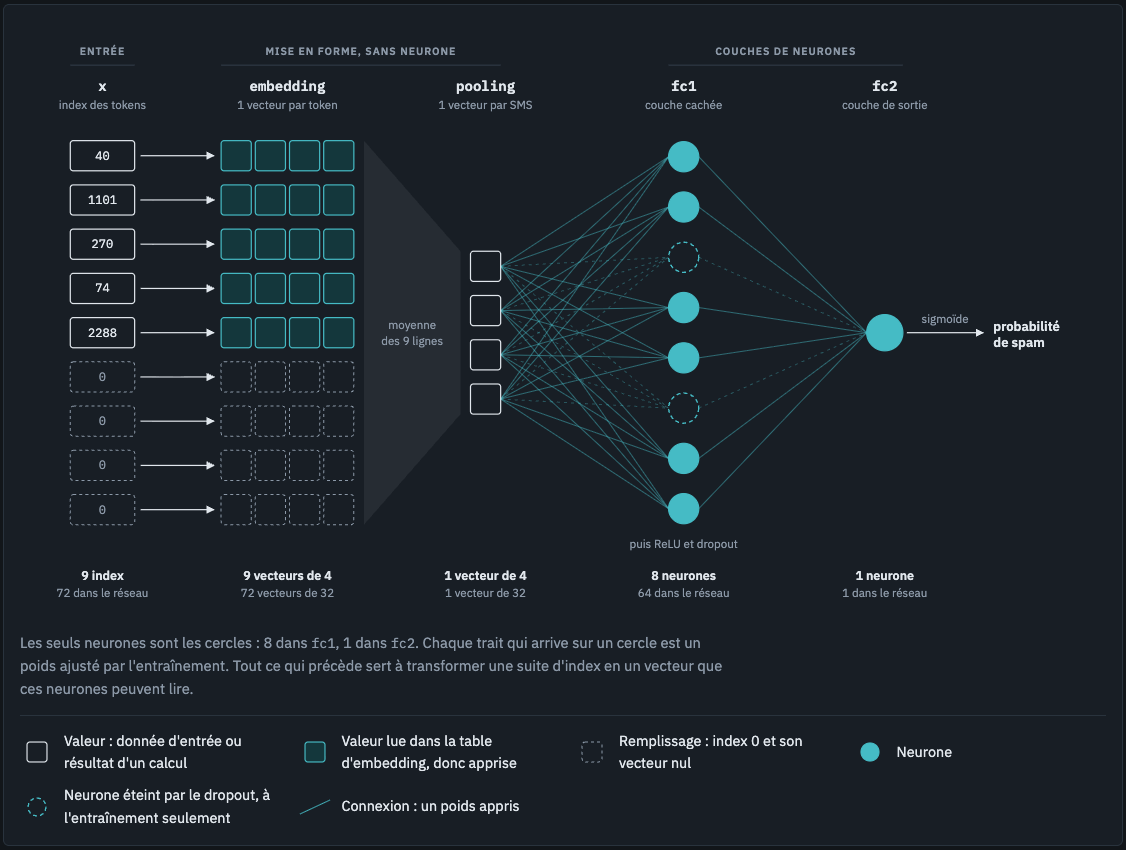

### Entraînement

Il faut maintenant entraîner le réseau sur le jeu d'entraînement tout en suivant l'évolution au niveau du jeu de validation. 
La bibliothèque PyTorch nécessite que les boucles soient intégralement écrites, contrairement a scikit-learn qui fournit la fonction fit. Nous allons donc définir ces éléments:
- La fonction de perte
- l'optimiseur Adam
- la fonction d'entrainement

#### La fonction de perte
Il s'agit de la binary cross-entropy. Elle est adaptée à une sortie sigmoide pour un usage en classification binaire. 

#### L'optimiseur Adam
Adam optimise eb appliquant les corrections aux parametre en fonction des gradiant. Il permet generalement une convergence plus rapide.
Le pas d'apprentissage recommandé est 0.001.

#### La fonction d'entraînement
Elle permet de parcourir les epoch. Nous la recuperons du cours sur le deep learning
À chaque époque, la fonction parcourt les mini-batches du jeu d'entraînement et, pour chacun d'entre eux, elle calcule la prédiction et mesure l'erreur. Elle effectue ensuite la backward propagation et ajuste les parametres. 

In [21]:
import torch.optim as optim

criterion = nn.BCELoss()                                                             #Choix de la Binary Cross-Enthropy pour fonction de cout.
optimizer = optim.Adam(model.parameters(), lr=0.001)

def train(model, train_loader, val_loader, criterion, optimizer, epochs):
    history = {"loss": [], "val_loss": [], "accuracy": [], "val_accuracy": []}
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        correct = 0
        for inputs, labels in train_loader:
            optimizer.zero_grad()                                                    #Oublier les gradients du paquet précédent
            outputs = model(inputs)                                                  #Prediction à l'aide de la fonction modele definie precedement
            loss = criterion(outputs, labels)                                        #Calcul de l'erreur du paquet 
            loss.backward()                                                          #Calcul des gradiants
            optimizer.step()                                                         #Correction des parametres
            running_loss += loss.item()
            correct += ((outputs > 0.5) == labels).sum().item()
        history["loss"].append(running_loss / len(train_loader))
        history["accuracy"].append(correct / len(train_loader.dataset))

        model.eval()
        running_loss = 0.0
        correct = 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                running_loss += loss.item()
                correct += ((outputs > 0.5) == labels).sum().item()
        history["val_loss"].append(running_loss / len(val_loader))
        history["val_accuracy"].append(correct / len(val_loader.dataset))

        print(f"Epoch {epoch + 1}/{epochs}, Loss: {history['loss'][-1]:.4f}, Val Loss: {history['val_loss'][-1]:.4f}, "
              f"Acc: {history['accuracy'][-1]:.4f}, Val Acc: {history['val_accuracy'][-1]:.4f}")
    return history

history = train(model, train_loader, val_loader, criterion, optimizer, epochs=10)

Epoch 1/10, Loss: 0.5779, Val Loss: 0.4170, Acc: 0.8224, Val Acc: 0.8747
Epoch 2/10, Loss: 0.3221, Val Loss: 0.2386, Acc: 0.8784, Val Acc: 0.8953
Epoch 3/10, Loss: 0.1750, Val Loss: 0.1333, Acc: 0.9443, Val Acc: 0.9587
Epoch 4/10, Loss: 0.0969, Val Loss: 0.0977, Acc: 0.9745, Val Acc: 0.9729
Epoch 5/10, Loss: 0.0642, Val Loss: 0.0835, Acc: 0.9825, Val Acc: 0.9742
Epoch 6/10, Loss: 0.0484, Val Loss: 0.0755, Acc: 0.9878, Val Acc: 0.9793
Epoch 7/10, Loss: 0.0363, Val Loss: 0.0715, Acc: 0.9906, Val Acc: 0.9793
Epoch 8/10, Loss: 0.0262, Val Loss: 0.0670, Acc: 0.9928, Val Acc: 0.9793
Epoch 9/10, Loss: 0.0201, Val Loss: 0.0660, Acc: 0.9942, Val Acc: 0.9819
Epoch 10/10, Loss: 0.0153, Val Loss: 0.0644, Acc: 0.9964, Val Acc: 0.9819


### Courbes d'apprentissage

L'evolution de la loss et de l'accuracy sont suivies et representées sur le diagrame ci-dessous.

In [22]:
history_df = pd.DataFrame(history)
history_df["epoch"] = history_df.index + 1

fig = px.line(history_df, x="epoch", y=["loss", "val_loss"], markers=True,
              labels={"value": "perte", "variable": "jeu"},
              title="Perte par epoch, entraînement et validation")
fig.show()

In [23]:
fig = px.line(history_df, x="epoch", y=["accuracy", "val_accuracy"], markers=True,
              labels={"value": "accuracy", "variable": "jeu"},
              title="Accuracy par epoch, entraînement et validation")
fig.show()

### Détermination du nombre d'epochs

La perte diminue rapidement pour els 5 premieres epochs pour les deux jeux: train et validation. La perte sur train se poursuit alors que celle de Validation se stabilise autour de 0,065. Toutefois, nous n'observons pas encore de remontée de la loss, nous poursuivons donc en poussant le nombre d'epoch à 30.

In [24]:
torch.manual_seed(42)
model_30 = TextClassifier(vocab_size=tokenizer.n_vocab, embed_dim=32, hidden_dim=64)
optimizer_30 = optim.Adam(model_30.parameters(), lr=0.001)
history_30 = train(model_30, train_loader, val_loader, criterion, optimizer_30, epochs=30)

Epoch 1/30, Loss: 0.5779, Val Loss: 0.4170, Acc: 0.8224, Val Acc: 0.8747
Epoch 2/30, Loss: 0.3221, Val Loss: 0.2386, Acc: 0.8784, Val Acc: 0.8953
Epoch 3/30, Loss: 0.1750, Val Loss: 0.1333, Acc: 0.9443, Val Acc: 0.9587
Epoch 4/30, Loss: 0.0969, Val Loss: 0.0977, Acc: 0.9745, Val Acc: 0.9729
Epoch 5/30, Loss: 0.0642, Val Loss: 0.0835, Acc: 0.9825, Val Acc: 0.9742
Epoch 6/30, Loss: 0.0484, Val Loss: 0.0755, Acc: 0.9878, Val Acc: 0.9793
Epoch 7/30, Loss: 0.0363, Val Loss: 0.0715, Acc: 0.9906, Val Acc: 0.9793
Epoch 8/30, Loss: 0.0262, Val Loss: 0.0670, Acc: 0.9928, Val Acc: 0.9793
Epoch 9/30, Loss: 0.0201, Val Loss: 0.0660, Acc: 0.9942, Val Acc: 0.9819
Epoch 10/30, Loss: 0.0153, Val Loss: 0.0644, Acc: 0.9964, Val Acc: 0.9819
Epoch 11/30, Loss: 0.0119, Val Loss: 0.0643, Acc: 0.9972, Val Acc: 0.9806
Epoch 12/30, Loss: 0.0097, Val Loss: 0.0638, Acc: 0.9975, Val Acc: 0.9806
Epoch 13/30, Loss: 0.0072, Val Loss: 0.0656, Acc: 0.9989, Val Acc: 0.9806
Epoch 14/30, Loss: 0.0055, Val Loss: 0.0666, Ac

#### Courbes d'apprentissage

In [25]:
history_30_df = pd.DataFrame(history_30)
history_30_df["epoch"] = history_30_df.index + 1

fig = px.line(history_30_df, x="epoch", y=["loss", "val_loss"], markers=True,
              labels={"value": "perte", "variable": "jeu"},
              title="Perte par epoch sur 30 epochs, entraînement et validation")
fig.show()


In [26]:
fig = px.line(history_30_df, x="epoch", y=["accuracy", "val_accuracy"], markers=True,
              labels={"value": "accuracy", "variable": "jeu"},
              title="Accuracy par epoch sur 30 epochs, entraînement et validation")
fig.show()
print(history_30_df["val_loss"].idxmin() + 1, history_30_df["val_loss"].min())

12 0.0637574765458703


#### Observations

La loss sur le jeu de validation atteint un minimum à l'epoch 12 et vaut 0,064. Après cela, elle remonte pour atteindre 0,085 à l'epoch 30. La loss sur le jeu d'entraînement, quant à elle, tend vers zéro. C'est le signe d'un surapprentissage. Le modèle finit par apprendre le jeu d'entraînement et généralise moins bien. 
L'accuracy sur le jeu de validation, quant à elle, reste stable entre 98,1 % et 98,5 % alors qu'elle ateind 100% sur l'entrainement.
Les symptômes du surapprentissage sont visibles sur la loss, mais pas sur l'accuracy. D'une manière générale, nous pouvons conclure que le modèle se trompe toujours sur les mêmes SMS, mais avec une confiance croissante. La BCE penalise les erreurs faite avec confiance (probabilité elevee accodé a une prevision qui s'avere erronnée).

Au vu de ces données, nous allons retenir un modèle avec 12 epochs. Cela correspond au point où les pertes sont minimales sur le jeu de validation. C'est ce modèle-là qui sera évalué sur le jeu de test. 

### Réentraînement du modèle sur 12 epochs

In [27]:
torch.manual_seed(42)
model_12 = TextClassifier(vocab_size=tokenizer.n_vocab, embed_dim=32, hidden_dim=64)
optimizer_12 = optim.Adam(model_12.parameters(), lr=0.001)
history_12 = train(model_12, train_loader, val_loader, criterion, optimizer_12, epochs=12)

Epoch 1/12, Loss: 0.5779, Val Loss: 0.4170, Acc: 0.8224, Val Acc: 0.8747
Epoch 2/12, Loss: 0.3221, Val Loss: 0.2386, Acc: 0.8784, Val Acc: 0.8953
Epoch 3/12, Loss: 0.1750, Val Loss: 0.1333, Acc: 0.9443, Val Acc: 0.9587
Epoch 4/12, Loss: 0.0969, Val Loss: 0.0977, Acc: 0.9745, Val Acc: 0.9729
Epoch 5/12, Loss: 0.0642, Val Loss: 0.0835, Acc: 0.9825, Val Acc: 0.9742
Epoch 6/12, Loss: 0.0484, Val Loss: 0.0755, Acc: 0.9878, Val Acc: 0.9793
Epoch 7/12, Loss: 0.0363, Val Loss: 0.0715, Acc: 0.9906, Val Acc: 0.9793
Epoch 8/12, Loss: 0.0262, Val Loss: 0.0670, Acc: 0.9928, Val Acc: 0.9793
Epoch 9/12, Loss: 0.0201, Val Loss: 0.0660, Acc: 0.9942, Val Acc: 0.9819
Epoch 10/12, Loss: 0.0153, Val Loss: 0.0644, Acc: 0.9964, Val Acc: 0.9819
Epoch 11/12, Loss: 0.0119, Val Loss: 0.0643, Acc: 0.9972, Val Acc: 0.9806
Epoch 12/12, Loss: 0.0097, Val Loss: 0.0638, Acc: 0.9975, Val Acc: 0.9806


### Évaluation sur le jeu de test

In [28]:
from sklearn.metrics import classification_report, confusion_matrix

model_12.eval()
with torch.no_grad():
    y_test_proba = model_12(X_test_tensor)
y_test_pred = (y_test_proba > 0.5).int().numpy()

print(confusion_matrix(y_test, y_test_pred))
print(classification_report(y_test, y_test_pred, target_names=["ham", "spam"], digits=3))

[[675   3]
 [  8  88]]
              precision    recall  f1-score   support

         ham      0.988     0.996     0.992       678
        spam      0.967     0.917     0.941        96

    accuracy                          0.986       774
   macro avg      0.978     0.956     0.967       774
weighted avg      0.986     0.986     0.986       774



 Le modèle proposé atteint 98,6 % d'accuracy. En comparaison, un modèle qui classerait tout en ham obtiendrait 87,6% ((675+3)/(675+3+8+88) = 0.876). 

 Le seuil de 0.5 est arbitraire. Il doit être défini suivant le besoin prioritaire: soit bloquer le plus de spams possible, au prix de quelques messages légitimes bloqués, soit ne bloquer aucun message légitime, au prix de laisser passer quelques spams.
 Dans la cellule ci-dessous, nous allons étudier l'effet d'un changement de seuil sur les métriques les plus pertinentes, c'est-à-dire la precision, le recall et le F1 score. 

### Choix du seuil de décision

#### Étude de l'effet du seuil sur les métriques

In [29]:
from sklearn.metrics import precision_score, recall_score, f1_score

with torch.no_grad():
    y_val_proba = model_12(X_val_tensor).numpy()

thresholds = np.arange(0.1, 0.95, 0.05)
threshold_df = pd.DataFrame({
    "threshold": thresholds,
    "precision": [precision_score(y_val, y_val_proba > t) for t in thresholds],
    "recall": [recall_score(y_val, y_val_proba > t) for t in thresholds],
    "f1": [f1_score(y_val, y_val_proba > t) for t in thresholds],
})
print(threshold_df.round(3).to_string(index=False))

fig = px.line(threshold_df, x="threshold", y=["precision", "recall", "f1"], markers=True,
              labels={"value": "score sur la classe spam", "variable": "métrique", "threshold": "seuil"},
              title="Précision, rappel et F1 de la classe spam selon le seuil, jeu de validation")
fig.show()

 threshold  precision  recall    f1
      0.10      0.883   0.938 0.910
      0.15      0.918   0.918 0.918
      0.20      0.926   0.907 0.917
      0.25      0.946   0.907 0.926
      0.30      0.956   0.897 0.926
      0.35      0.956   0.887 0.920
      0.40      0.956   0.887 0.920
      0.45      0.966   0.876 0.919
      0.50      0.966   0.876 0.919
      0.55      0.966   0.876 0.919
      0.60      0.977   0.876 0.924
      0.65      0.977   0.876 0.924
      0.70      0.977   0.876 0.924
      0.75      0.988   0.876 0.929
      0.80      0.988   0.876 0.929
      0.85      0.988   0.876 0.929
      0.90      0.988   0.856 0.917


Nous considérons que bloquer un message légitime (ham) est nettement plus nuisible que de laisser passer quelques spams. L'objectif de ces courbes est de choisir un seuil qui limite au maximum les hams bloqués à tort (faux positifs) tout en conservant un bon niveau de spams détectés.

Nous constatons que le seuil de 0,5 n'était pas un choix optimal. 
En déplaçant le seuil vers des valeurs plus élevées, nous constatons qu'il est possible d'augmenter la précision (c'est-à-dire le nombre de spam detectés correctement par rapports au cas evalué positif) sans faire baisser le recall, et donc en faisant croite le F1.

Le seuil de 0,8 est celui qui constitue le meilleur équilibre entre les trois métriques et celui que nous conservons. 

#### Évaluation sur le jeu de test avec le seuil retenu

In [30]:
threshold = 0.8
y_test_pred = (y_test_proba > threshold).int().numpy()

print(confusion_matrix(y_test, y_test_pred))
print(classification_report(y_test, y_test_pred, target_names=["ham", "spam"], digits=3))

[[675   3]
 [ 12  84]]
              precision    recall  f1-score   support

         ham      0.983     0.996     0.989       678
        spam      0.966     0.875     0.918        96

    accuracy                          0.981       774
   macro avg      0.974     0.935     0.954       774
weighted avg      0.980     0.981     0.980       774



La précision obtenue à l'issue du test est de 0,966 sur les spams, Le recall de 0,875. Ces scores sont légèrement inférieurs à ceux que nous avions obtenu avec un seuil à 0,5. C'est quand le F1 score est également moins élevé, avec 0,918 pour un seuil à 0,8, Contre 0,941 pour un seuil à 0,5.

Globalement, le résultat obtenu sur le test ne s'aligne pas avec nos attentes. 

- D'une part, ces écarts doivent être relativisés par rapport au fait que le nombre de spam concernés lors de ces ecarts est faible: la différence est essentiellement de 4 spams manqués sur 96 à 0,8 et détectés à 0,5. Sur la validation, le gain qui avait motivé le choix de 0,8 portait lui aussi sur 2 hams sur 677. Ces différences peuvent raisonnablement être attribuées à des fluctuations. 

- D'autre part, un seuil élevé est ce qui nous protège du risque de bloquer des hams de manière trop fréquente, Ce qui est le principal risque de ce type de modèle. 

- Enfin, la décision du seuil ne peut pas porter sur le résultat obtenu à l'occasion d'un test, car cela constituerait de facto une forme de data leaking. Il s'agit d'un data leaking discret qui passe par le programmeur. 

Conserver un seuil à 0,8, en dépit de scores objectivement moins performants sur le test, s'aligne non seulement avec la prudence à attribuer à ce type de modèle, mais également avec les bonnes pratiques décisionnelles en data science. 


### Conclusion sur le premier modèle

Le réseau que nous avons construit a été entraîné sur 12 epochs et a utilisé un seuil de 0,8 en considération de la priorité accordée au non-blocage des hams. Les résultats sur le jeu de test sont de 98,1 % pour l'accuracy, 96,6 % pour la précision et 87,5 % pour le recall sur la classe des spams. 

Nous allons maintenant étudier un deuxième modèle, avec cette fois-ci du transfer learning, et la comparaison entre les deux modèles sera effectuée sur cette base. 

## 4. Second modèle : transfer learning

Dans le premier modèle, les vecteurs de tokens avaient été appris sur la base de nos seuls SMS et à destination exclusive de la détection de spam, mais ce modèle n'avait pas de capacité de compréhension sémantique à hauteur de ce que peuvent faire les modèles entraînés avec des couches d'attention.

Dans cette nouvelle approche, nous allons étudier un deuxième modèle basé sur le transfer learning. Cette fois-ci, nous allons nous baser sur un modèle pré-entraîné à l'aide d'un très grand corpus de textes en anglais. Nous allons ensuite utiliser notre propre corpus simplement pour affiner le modèle.

Le modèle sélectionné est DistilBERT, dans sa version de base sans distinction de casse (distilbert-base-uncased), publié sur Hugging Face :
https://huggingface.co/distilbert/distilbert-base-uncased

Ce modèle est choisi sur la base de ce que nous avons pu étudier en cours, mais surtout pour ses caractéristiques qui le rendent particulièrement adapté à la tâche que nous cherchons à réaliser. On peut lire notamment dans sa documentation technique sur Hugging Face la recommandation suivante : "Note that this model is primarily aimed at being fine-tuned on tasks that use the whole sentence (potentially masked) to make decisions, such as sequence classification, token classification or question answering." Autrement dit, un modèle destiné à être affiné sur des tâches qui décident à partir de la phrase entière, dont la classification de séquences : c'est notre cas.

Il dispose d'un vocabulaire de tokens dont les vecteurs d'embedding sont déjà appris, ainsi que de couches d'attention entraînées. Nous n'y ajouterons qu'une tête de classification, entraînée sur nos SMS.

La démarche que nous allons utiliser restera toutefois identique : un suivi sur la validation avec choix du seuil, et mesure des performances sur le test.


### Tokenisation avec le tokenizer de DistilBERT

Un nouveau modèle nécessite ici un nouveau tokenizer. Nous avions dans le premier modèle utilisé tiktoken. Le modèle s'appuie sur le vocabulaire de tokens qui lui est propre, et donc sur le tokenizer qui a été utilisé pour son entraînement.

Le chargement du tokenizer peut se faire par deux méthodes différentes. Nous avons vu en cours un outil appelé AutoTokenizer, alors que DistilBertTokenizer est recommandé sur le site de Hugging Face. En fait, AutoTokenizer appelle, pour ce modèle, DistilBertTokenizer, et donc nous allons l'utiliser directement, conformément à la documentation.

En résumé, nous considérons les outils suivants :

- bibliothèque : transformers, la bibliothèque de Hugging Face, qui s'appuie sur PyTorch ;
- modèle (checkpoint) : distilbert-base-uncased, les fichiers publiés sur Hugging Face, vocabulaire et poids ;
- tokenizer : la classe DistilBertTokenizer, chargée avec le vocabulaire de ce checkpoint.

Dans les cellules ci-dessous nous allons vérifier le découpage sur un message, puis observer la distribution des longueurs en tokens par classe, qui servira à fixer la longueur commune à l'étape suivante.


In [31]:
from transformers import DistilBertTokenizer

checkpoint = "distilbert-base-uncased"                                                    #designation du modele
bert_tokenizer = DistilBertTokenizer.from_pretrained(checkpoint)                          #chargement du tokenizer correspondant

encoded = bert_tokenizer(X_train.iloc[0])                                                 #decoupage en token du premier SMS
print(X_train.iloc[0])
print(encoded["input_ids"])
print(bert_tokenizer.convert_ids_to_tokens(encoded["input_ids"]))
print(bert_tokenizer.vocab_size)

I also thk too fast... Xy suggest one not me. U dun wan it's ok. Going 2 rain leh where got gd.
[101, 1045, 2036, 16215, 2243, 2205, 3435, 1012, 1012, 1012, 1060, 2100, 6592, 2028, 2025, 2033, 1012, 1057, 24654, 14071, 2009, 1005, 1055, 7929, 1012, 2183, 1016, 4542, 3393, 2232, 2073, 2288, 1043, 2094, 1012, 102]
['[CLS]', 'i', 'also', 'th', '##k', 'too', 'fast', '.', '.', '.', 'x', '##y', 'suggest', 'one', 'not', 'me', '.', 'u', 'dun', 'wan', 'it', "'", 's', 'ok', '.', 'going', '2', 'rain', 'le', '##h', 'where', 'got', 'g', '##d', '.', '[SEP]']
30522


#### Longueur des messages en tokens

Pour le premier modèle, nous allons mesurer la longueur de chaque SMS en tokens mais avec ce nouveau tokenizer.

In [32]:
bert_lens = pd.Series([len(bert_tokenizer(text)["input_ids"]) for text in X_train], index=X_train.index)
bert_lens.groupby(y_train).describe(percentiles=[0.5, 0.9, 0.95, 0.99])

,count,mean,std,min,50%,90%,95%,99%,max
label,,,,,,,,,
0,3161.0,22.097438,15.196581,3.0,17.0,42.0,49.0,78.4,186.0
1,449.0,44.409800,11.700370,8.0,46.0,57.2,61.0,66.0,70.0


La médiane de longueur pour les spam est de 46 tokens et 17 pour les hams. Leurs maximums sont respectivement de 70 et 186. Les longueurs sont un peu plus élevées que ce que nous avions obtenu avec tiktoken, mais le résultat est globalement le même. Les spams sont plus longs et plus homogènes que les hams. En conséquence, l'approche sera la même: la longueur commune devra dépasser celle du spam le plus long.  

#### Longueur commune

Sur la base de notre travail précédent, nous allons simplement appliquer la même règle. Nous fixons la longueur commune juste au-dessus du 99e percentile des longueurs du jeu d'entraînement. Nous vérifions d'abord le nombre de messages tronqués par classe. 

In [33]:
bert_max_length = int(np.percentile(bert_lens, 99)) + 1
print(bert_max_length)
print((bert_lens > bert_max_length).groupby(y_train).sum())

74
label
0    35
1     0
dtype: int64


La longueur à laquelle nous coupons est cette fois-ci de 74 tokens contre 72 avec tiktoken. Comme précédemment, aucun spam ne sera tronqué sur le jeu d'entraînement. Le plus long spam fait 70 tokens de longueur. 35 hams de taille particulièrement longue sont tronqués. Cela représente un peu plus de 1 % du jeu d'entraînement. 

#### Tokenisation des trois jeux

Le tokenizer de DistilBERT bert_tokenizer(...) permet de faire automatiquement le remplissage de zéro que nous avions fait précédemment de manière manuelle. Pour cela, on utilise l'argument padding="max_length"
on peut ensuite demander de tronquer la longueur à l'aide de truncation=True et en specifiant la longueur: max_length. return_tensors retournera un tenseur pytorch


In [34]:
# definition de la fonction de tokenisation encode_texts

def encode_texts(texts):
    return bert_tokenizer(list(texts), padding="max_length", truncation=True,
                          max_length=bert_max_length, return_tensors="pt")


#On reutilise les ensembles d'entrainement, de validation et de test definis precedement lors de la preparation des données
# creation des tenseurs d'entrainement, de validation et de test.

train_encodings = encode_texts(X_train)                                                    
val_encodings = encode_texts(X_val)
test_encodings = encode_texts(X_test)

print(train_encodings["input_ids"].shape, train_encodings["attention_mask"].shape)
print(train_encodings["input_ids"][0])
print(train_encodings["attention_mask"][0])

torch.Size([3610, 74]) torch.Size([3610, 74])
tensor([  101,  1045,  2036, 16215,  2243,  2205,  3435,  1012,  1012,  1012,
         1060,  2100,  6592,  2028,  2025,  2033,  1012,  1057, 24654, 14071,
         2009,  1005,  1055,  7929,  1012,  2183,  1016,  4542,  3393,  2232,
         2073,  2288,  1043,  2094,  1012,   102,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0])
tensor([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0])


#### Création des DataLoader

In [35]:
#Creation des data loader

bert_train_loader = DataLoader(TensorDataset(train_encodings["input_ids"], train_encodings["attention_mask"], y_train_tensor),
                               batch_size=batch_size, shuffle=True)
bert_val_loader = DataLoader(TensorDataset(val_encodings["input_ids"], val_encodings["attention_mask"], y_val_tensor),
                             batch_size=batch_size, shuffle=False)
bert_test_loader = DataLoader(TensorDataset(test_encodings["input_ids"], test_encodings["attention_mask"], y_test_tensor),
                              batch_size=batch_size, shuffle=False)
print(len(bert_train_loader), len(bert_val_loader), len(bert_test_loader))

113 25 25


### Chargement du modèle


Nous allons maintenant charger le modèle DistilBERT. 
D'après la page de présentation sur Hugging Face, le modèle possède 67 millions de paramètres. Nous avons donc besoin d'un accélérateur de calcul Afin de réduire le temps d'entraînement. 

Nous allons etablir egalement la structure du reseau à partir de la classe DistilBertForSequenceClassification.

Le nombre de sorties de la tête de classification est fixé à 1 (num_labels=1) : le modèle produit un score unique par message. Il est transformé en probabilité par une sigmoïde. On reprend la meme demarche qu'au premier modèle, La même démarche d'évaluation sera donc la meme sur la suite. 


Le modèle DistilBertForSequenceClassification possède deux couches non entraînées sur lesquelles des coefficients aléatoires sont implémentés, ce sont deux couches abscentes du checkpoint. Une fonctionnalité permet de rendre cet aléa répétable au besoin. Ces couches seront celles qui vont être le plus impactées par l'entraînement du modèle. Elles sont constituées d'une couche cachée de type pre-classifier et d'une couche de sortie d'un neurone. 

Recapitulatif des differents elements utilisés jusqu'ici, de leur nature et de leur role.

| nom | nature | description |
|---|---|---|
| transformers | bibliothèque | l'ensemble des fonctionnalités de Hugging Face pour charger, utiliser et entraîner des modèles |
| DistilBertTokenizer | classe (tokenizer) | la façon de découper un texte en tokens et de les convertir en numéros, à partir d'un vocabulaire |
| distilbert-base-uncased | checkpoint | les fichiers publiés du modèle : le vocabulaire du tokenizer et les poids de tous les neurones, dont les vecteurs d'embedding |
| DistilBertForSequenceClassification | classe (modèle) | la structure du réseau : les couches, leurs connexions, et la tête de classification au bout |


Nous chargeons ici le modèle une première fois afin d'examiner sa composition : 
- nombre de paramètres
- couche de sortie
- architecture. 
  
Pour les entraînements, le modele sera rechargé a chaque fois, afin de repartir du modele d'origine.

In [36]:
from transformers import DistilBertForSequenceClassification

device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"                #choix du processeur de calcul
print(device)

torch.manual_seed(42)                                                                                               #poids de la tete de classification tirés au hasard mais de maniere repetable.
bert_model = DistilBertForSequenceClassification.from_pretrained(checkpoint, num_labels=1).to(device)               #import de la structure du reseau de neurone et de leurs poids


print(sum(p.numel() for p in bert_model.parameters()))
print(bert_model.classifier)

mps


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


66954241
Linear(in_features=768, out_features=1, bias=True)


#### Aperçu du modèle

In [37]:
print(bert_model)

DistilBertForSequenceClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSdpaAttention(
            (dropout): Dropout(p=0.1, inplace=False)
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
          (ffn): FFN(
            (dropout): Dropout(p=0.1, inplace=False)


#### Représentation globale

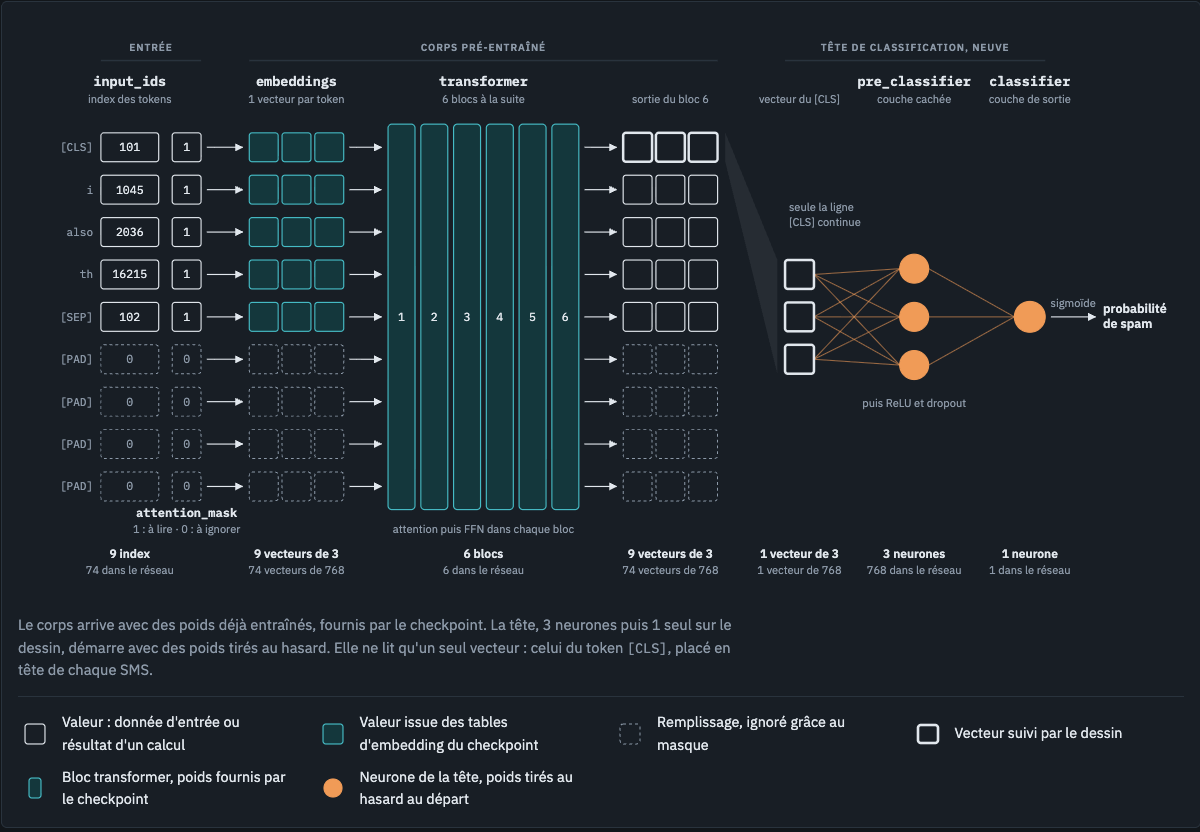

#### À l'intérieur d'un bloc

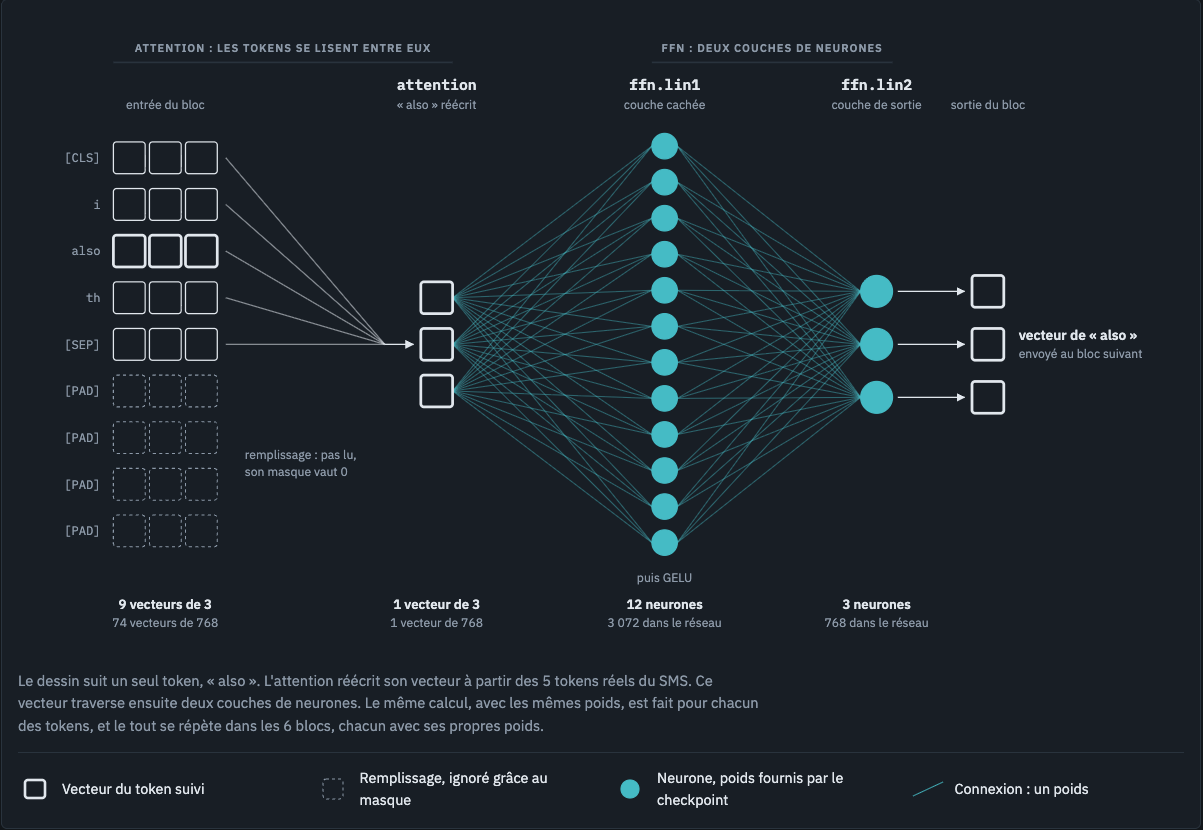
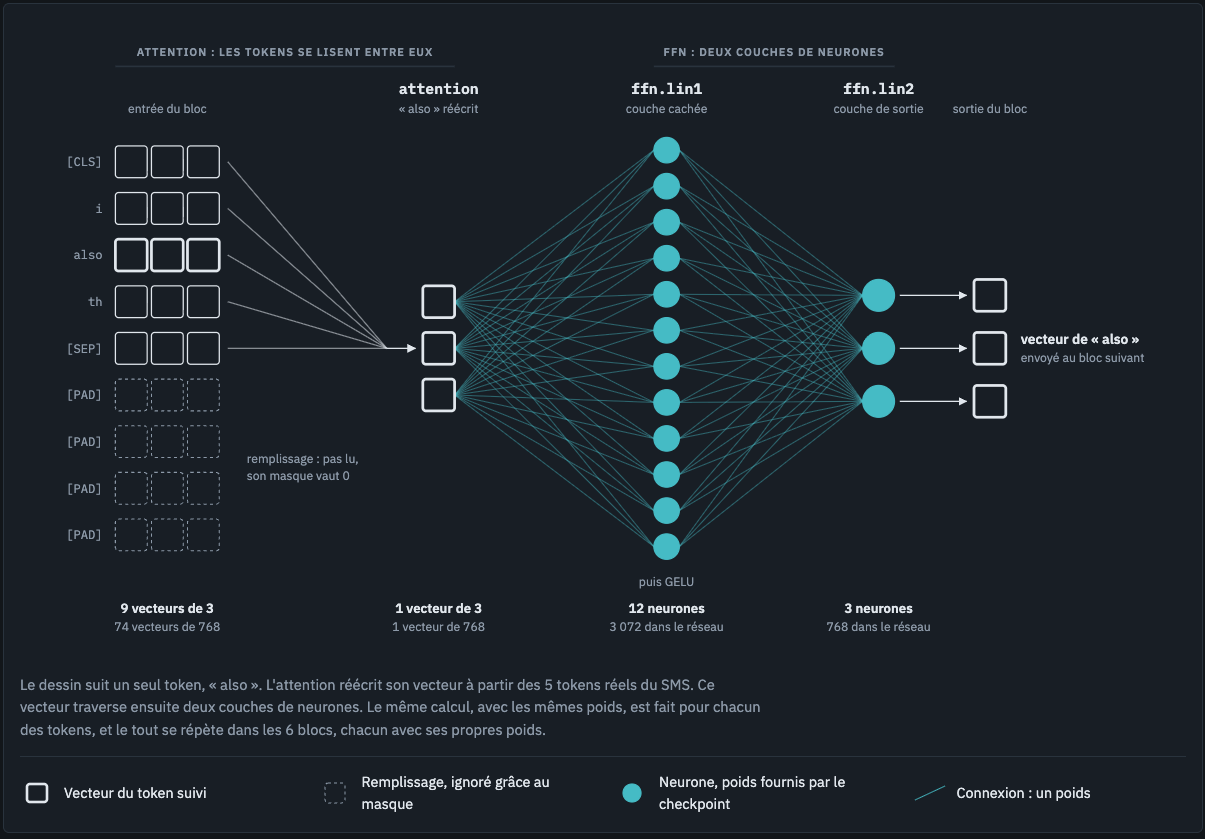

### Entraînement

#### La fonction d'entraînement

La fonction d'entraînement est fondamentalement la même que celle du premier modèle, avec la même fonction de perte, c'est-à-dire la BCE. Nous devons simplement faire trois ajustements:

- Deux entrées sont necessaires pour chaque message : les identifiants de tokens et le masque d'attention. Chaque paquet contient donc trois éléments au lieu de deux : ces deux entrées, et les étiquettes. LEs etiquettes servent à comparer lam sortie avec le resultat du reseau pour determiner la backward propagation.
- Le premier modèle appliquait une sigmoïde au niveau de sa derniere couche et renvoyait une probabilité. DistilBERT s'arrete une étape avant et renvoie un logit. La fonction applique donc elle-même la sigmoïde à ce score pour obtenir la probabilité de spam.
- Le modèle étant placé sur l'accélérateur de calcul, chaque paquet doit y être envoyé aussi.

In [38]:
def train_bert(model, train_loader, val_loader, criterion, optimizer, epochs):                                            #Nous reprenons la structure de la premiere fonction                   
    history = {"loss": [], "val_loss": [], "accuracy": [], "val_accuracy": []} 
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        correct = 0
        for input_ids, attention_mask, labels in train_loader:                                                            #Chaque paquet contient ces 3 elements
            input_ids, attention_mask, labels = input_ids.to(device), attention_mask.to(device), labels.to(device)        #envoie des elements au processeur
            optimizer.zero_grad()                                                                                         #oublie des gradiants precedents
            logits = model(input_ids=input_ids, attention_mask=attention_mask).logits                                     #Les 2 entrees sont recue par le modele qui retourne un score brut
            outputs = torch.sigmoid(logits).squeeze(1)                                                                    #sigmoide : le score brut devient une probabilite de spam
            loss = criterion(outputs, labels)                                                                             #Calcul d el'erreur
            loss.backward()                                                                                               #calcul des gradiant et backward propagation
            optimizer.step()                                                                                              #correction des parametres
            running_loss += loss.item()
            correct += ((outputs > 0.5) == labels).sum().item()                                                           #seuil à 0,5
        history["loss"].append(running_loss / len(train_loader))
        history["accuracy"].append(correct / len(train_loader.dataset))

        model.eval()
        running_loss = 0.0
        correct = 0
        with torch.no_grad():                                                                                             #validation: meme calculs mais sans la partie apprentissage
            for input_ids, attention_mask, labels in val_loader:
                input_ids, attention_mask, labels = input_ids.to(device), attention_mask.to(device), labels.to(device)
                logits = model(input_ids=input_ids, attention_mask=attention_mask).logits
                outputs = torch.sigmoid(logits).squeeze(1)
                loss = criterion(outputs, labels)
                running_loss += loss.item()
                correct += ((outputs > 0.5) == labels).sum().item()
        history["val_loss"].append(running_loss / len(val_loader))
        history["val_accuracy"].append(correct / len(val_loader.dataset))

        print(f"Epoch {epoch + 1}/{epochs}, Loss: {history['loss'][-1]:.4f}, Val Loss: {history['val_loss'][-1]:.4f}, "
              f"Acc: {history['accuracy'][-1]:.4f}, Val Acc: {history['val_accuracy'][-1]:.4f}")
    return history

#### Premier entraînement sur 3 epochs

L'optimiseur est AdamW, variante d'Adam utilisée pour l'affinage, avec un pas d'apprentissage vingt fois plus petit que pour le premier modèle (soit 5e-5), afin de ne pas dégrader ce que le pré-entraînement a appris. Nous entraînons sur 3 epochs.
Il s'agit d'un modèle neuf, la seed est fixee de facon a ce que les poids de la tête de classification soient constament choisis de la même façon à chaque exécution.

In [39]:
bert_criterion = nn.BCELoss()                                                                                             #meme fonction de perte que le premier modele: la BCE

torch.manual_seed(42)                                                                                                     #poids de la tete de classification tirés au hasard mais de maniere repetable.
bert_model = DistilBertForSequenceClassification.from_pretrained(checkpoint, num_labels=1).to(device)                     #import de la structure du reseau de neurone et de leurs poids
bert_optimizer = optim.AdamW(bert_model.parameters(), lr=5e-5)                                                            #variante d'Adam avec un pas plus petit
bert_history = train_bert(bert_model, bert_train_loader, bert_val_loader, bert_criterion, bert_optimizer, epochs=3)

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch 1/3, Loss: 0.0966, Val Loss: 0.0598, Acc: 0.9693, Val Acc: 0.9845
Epoch 2/3, Loss: 0.0285, Val Loss: 0.0849, Acc: 0.9922, Val Acc: 0.9858
Epoch 3/3, Loss: 0.0176, Val Loss: 0.0392, Acc: 0.9950, Val Acc: 0.9884


Nous constatons que dès la première époque, l'accuracy est plus elevee que celle du premier model au bout de 12 epochs (98,4% contre 98.1%).

À la troisième epoch, la perte de validation est de 0,039, contre 0,064 pour le premier modèle, et l'accuracy de validation de 98,8 %.

Nous observons egalement que la perte sur le jeu de validation varie d'abord à la hausse avant de redescendre.
Trois epochs ne suffisent pas à établir où se situe le minimum de la perte de validation.   
Nous allons maintenant rechercher le nombre optimal d'epochs


### Détermination du nombre d'epochs

Nous allons maintenant entrainer le modele sur un plus grand nombre d'epoch. Nous allons le faire ici sur 10 epochs. Nous presumons que ce nombre sera probablement trop grand et que du suraprentissage est à prevoir, mais le but est precisement de savoir à quel moment il a lieu, d'observer le retournement de la courbe des pertes pour determiner le bon nombre d'epoch.

In [40]:
torch.manual_seed(42)
bert_model_10 = DistilBertForSequenceClassification.from_pretrained(checkpoint, num_labels=1).to(device)
bert_optimizer_10 = optim.AdamW(bert_model_10.parameters(), lr=5e-5)
bert_history_10 = train_bert(bert_model_10, bert_train_loader, bert_val_loader, bert_criterion, bert_optimizer_10, epochs=10)

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch 1/10, Loss: 0.0966, Val Loss: 0.0598, Acc: 0.9693, Val Acc: 0.9845
Epoch 2/10, Loss: 0.0285, Val Loss: 0.0849, Acc: 0.9922, Val Acc: 0.9858
Epoch 3/10, Loss: 0.0176, Val Loss: 0.0394, Acc: 0.9950, Val Acc: 0.9884
Epoch 4/10, Loss: 0.0081, Val Loss: 0.0729, Acc: 0.9981, Val Acc: 0.9858
Epoch 5/10, Loss: 0.0111, Val Loss: 0.1033, Acc: 0.9972, Val Acc: 0.9793
Epoch 6/10, Loss: 0.0069, Val Loss: 0.0547, Acc: 0.9983, Val Acc: 0.9910
Epoch 7/10, Loss: 0.0041, Val Loss: 0.0544, Acc: 0.9992, Val Acc: 0.9910
Epoch 8/10, Loss: 0.0004, Val Loss: 0.0665, Acc: 1.0000, Val Acc: 0.9910
Epoch 9/10, Loss: 0.0002, Val Loss: 0.0716, Acc: 1.0000, Val Acc: 0.9910
Epoch 10/10, Loss: 0.0001, Val Loss: 0.0742, Acc: 1.0000, Val Acc: 0.9910


#### Courbes d'apprentissage

In [41]:
bert_history_10_df = pd.DataFrame(bert_history_10)
bert_history_10_df["epoch"] = bert_history_10_df.index + 1

fig = px.line(bert_history_10_df, x="epoch", y=["loss", "val_loss"], markers=True,
              labels={"value": "perte", "variable": "jeu"},
              title="DistilBERT : perte par epoch sur 10 epochs, entraînement et validation")
fig.show()
print(bert_history_10_df["val_loss"].idxmin() + 1, bert_history_10_df["val_loss"].min())

3 0.039361197920516136


In [42]:
fig = px.line(bert_history_10_df, x="epoch", y=["accuracy", "val_accuracy"], markers=True,
              labels={"value": "accuracy", "variable": "jeu"},
              title="DistilBERT : accuracy par epoch sur 10 epochs, entraînement et validation")
fig.show()

#### Observations
Les diagrammes en dent des scie obtenus sont plus difficiles à interpréter que ceux obtenus avec le premier modèle. 
Les dents de scie peuvent être causées notamment par la taille relativement faible du jeu de validation (97 spams sur 774 sms). Un aléa portant sur deux ou trois SMS plus difficiles que les autres à déterminer peut faire basculer le résultat de manière significative. 

La BCE amplifie cet effet, elle pénalise très fortement une erreur faite avec une grande confiance.

À partir de la 8eme epoch, l'accuracy sur le jeu d'entraînement atteint 100 %. La perte d'entraînement devient quand à elle qualisment nulle. C'est symptomatique d'un suraprentissage, le modele a simplement apris par coeur les données. Il peut d'ailleur le faire d'autant mieux qu'il dispose maintenant d'un plus grand nombre de parametre que dans le premier modele.

Le point difficile est le choix entre 3 et 6 epochs. Les deux valeurs presentes des resultats interessant et il convient de trancher.
Tout d'abord à 3 epochs, la perte de validation est la plus basse (0,039 contre 0,043 à 6 epochs), et l'écart entre la perte d'entraînement et la perte de validation est le plus faible. Cela signifie que le modèle généralise avec moins de surapprentissage. La partie pré-entraînée du modèle est aussi moins modifiée par l'entraînement. L'accuracy de validation est comparable dans les deux cas (98,8 % et 99,0 %). 

Nous retenons donc 3 epochs.

### Choix du seuil de décision

Comme pour le premier modèle, nous allons choisir le seuil sur le jeu de validation.

#### Fonction de prédiction

Elle permet de calculer la probabilité de spam de chaque message d'un jeu. 
Elle est basée sur la partie validation de la fonction d'entraînement. La sigmoïde transforme son score en probabilité. 

In [43]:
def predict_proba(model, loader):
    model.eval()
    probas = []
    with torch.no_grad():
        for input_ids, attention_mask, labels in loader:
            logits = model(input_ids=input_ids.to(device), attention_mask=attention_mask.to(device)).logits
            probas.append(torch.sigmoid(logits).squeeze(1).cpu())
    return torch.cat(probas).numpy()

#### Effet du seuil sur les métriques

Nous calculons d'abord la probabilité de spam de chaque message du jeu de validation. Pour différents seuils, nous calculons sur la classe spam :
- la précision
- le rappel
- le F1

In [44]:
bert_val_proba = predict_proba(bert_model, bert_val_loader)

bert_threshold_df = pd.DataFrame({
    "threshold": thresholds,
    "precision": [precision_score(y_val, bert_val_proba > t) for t in thresholds],
    "recall": [recall_score(y_val, bert_val_proba > t) for t in thresholds],
    "f1": [f1_score(y_val, bert_val_proba > t) for t in thresholds],
})
print(bert_threshold_df.round(3).to_string(index=False))



 threshold  precision  recall    f1
      0.10      0.756   0.990 0.857
      0.15      0.817   0.969 0.887
      0.20      0.847   0.969 0.904
      0.25      0.870   0.969 0.917
      0.30      0.903   0.959 0.930
      0.35      0.920   0.948 0.934
      0.40      0.929   0.948 0.939
      0.45      0.929   0.948 0.939
      0.50      0.958   0.948 0.953
      0.55      0.968   0.938 0.953
      0.60      0.978   0.938 0.958
      0.65      0.978   0.938 0.958
      0.70      0.978   0.938 0.958
      0.75      0.989   0.938 0.963
      0.80      0.989   0.938 0.963
      0.85      0.989   0.928 0.957
      0.90      0.989   0.918 0.952


In [45]:
fig = px.line(bert_threshold_df, x="threshold", y=["precision", "recall", "f1"], markers=True,
              labels={"value": "score sur la classe spam", "variable": "métrique", "threshold": "seuil"},
              title="DistilBERT : précision, rappel et F1 de la classe spam selon le seuil, jeu de validation")
fig.show()

#### Observations et choix du seuil

La précision augmente avec le seuil jusqu'à 0,989 à partir de 0,75, soit un seul ham bloqué à tort sur 677. Le rappel reste à 0,938 entre 0,55 et 0,80, puis diminue. Le F1 est maximal entre 0,75 et 0,80 (0,963).

Le seuil que nous retenons est de 0,80, comme pour le premier modèle. Ce choix est fondé sur les meme justifications que precedement, c'est à dire la priorité donnée au non-blocage des messages légitimes. 


### Évaluation sur le jeu de test

Nous allons maintenant évaler le modèle reten sur le jeu de test.   
Le nombre d'epochs retenu est de 3 et le seuil à 0.8.


In [46]:
bert_threshold = 0.8
bert_test_proba = predict_proba(bert_model, bert_test_loader)
bert_test_pred = (bert_test_proba > bert_threshold).astype(int)

print(confusion_matrix(y_test, bert_test_pred))
print(classification_report(y_test, bert_test_pred, target_names=["ham", "spam"], digits=3))

[[678   0]
 [  1  95]]
              precision    recall  f1-score   support

         ham      0.999     1.000     0.999       678
        spam      1.000     0.990     0.995        96

    accuracy                          0.999       774
   macro avg      0.999     0.995     0.997       774
weighted avg      0.999     0.999     0.999       774



Le modèle n'a commis qu'une seule erreur au niveau de la prédiction, et il s'agit d'un spam identifié en tant que ham, donc d'un spam qui a passé le filtre. Aucun des hams n'a été identifié en tant que spam, ce qui reste un objectif prioritaire et qui a été atteint de maniere très satisfaisante sur cet ensemble de test.

La precision sur les spam est de 100%, le recall est de 99% pour un F1 de 99.5%

Le resultat est meilleur que celui observé sur le jeu de validation ; cette difference puisse etre attribuee à la petitesse du jeu.


## 5. Comparaison des deux modèles et conclusion

Les deux modèles ont été évalués sur le même jeu de test de 774 SMS (678 hams, 96 spams), avec un seuil de décision de 0,80 choisi dans les deux cas sur le jeu de validation.

| | Premier modèle : réseau construit de zéro | Second modèle : DistilBERT affiné |
|---|---|---|
| Tokenizer | tiktoken (GPT-4) | tokenizer de DistilBERT |
| Nombre de paramètres | 3,2 millions | 67 millions |
| Origine des poids | appris sur nos SMS | pré-entraînés, puis affinés sur nos SMS |
| Nombre d'epochs retenu | 12 | 3 |
| Hams bloqués à tort | 3 | 0 |
| Spams non détectés | 12 | 1 |
| Précision (spam) | 96,6 % | 100 % |
| Rappel (spam) | 87,5 % | 99,0 % |
| F1 (spam) | 0,918 | 0,995 |
| Accuracy | 98,1 % | 99,9 % |

Les deux modèles nous ont permis d'atteindre l'objectif recherché: detecter la grande majorité des spams en bloquant très peu de messages légitimes.

Pour le premier modele, nous avons utilisé un réseau simple, facile à entrainer, qui a pu dépasser 98 % d'accuracy. 
Pour le deuxieme, nous avons utilisé le transfer learning en profitant d'un modele pre-entrainé. Nous avons ainsi réduit le nombre d'erreurs de 15 à 1. Le pre-entrainement premert de beficier d'une représentation du langage apprise sur un très grand corpus. Nptre corpus de 3 610 SMS a simplement permis de l'ajuster à un besoin specifique.

Il faut noter que le 2eme modele possede 20 fois plus de paramètres et plusieurs minutes ont été necessaire en depit d'un accélérateur de calcul.
Un operateur telphonique possedant simultanement une responsabilité elevée sur le transfer des messages mais aussi des moyens informatiques performant a un interet certain de considerer ce deuxieme modele.